In [ ]:
# ===== PDF EXPORT: run this cell by itself AFTER "Run all" has finished =====
# Makes a PDF of this notebook with nothing cut off: long code lines and printed text wrap onto the next line,
# and wide tables and figures shrink to fit the page. This cell is left out of the PDF.
# Google Colab: reads the notebook straight from the browser, so it includes every output (no need to save first).
# Jupyter / VS Code: save the notebook first (Ctrl+S / Cmd+S), since it reads the saved file.
RUN_PDF_EXPORT = False                      # set to True, then run only this cell
NOTEBOOK_FILE = "02_phase3_report.ipynb"                    # only used outside Colab
PDF_FILE = "02_phase3_report.pdf"

if not RUN_PDF_EXPORT:
    print('PDF export is off. After "Run all" finishes, set RUN_PDF_EXPORT = True and run only this cell.')
else:
    import json, os, subprocess, sys, tempfile
    import nbformat
    from nbconvert import HTMLExporter

    # 1. Get the notebook with all of its outputs
    try:
        from google.colab import _message, files
        nb_dict = _message.blocking_request("get_ipynb", timeout_sec=120)["ipynb"]
        in_colab = True
    except ImportError:
        with open(NOTEBOOK_FILE, encoding="utf-8") as f:
            nb_dict = json.load(f)
        in_colab = False
    nb = nbformat.reads(json.dumps(nb_dict), as_version=4)   # also normalizes Colab's format
    nb.cells = [c for c in nb.cells if "RUN_PDF_EXPORT" not in "".join(c.source)]   # leave this cell out

    # 2. Notebook -> HTML, plus print styles so nothing runs off the page
    try:
        exporter = HTMLExporter(template_name="lab")
        html, _ = exporter.from_notebook_node(nb)
    except Exception:
        exporter = HTMLExporter(template_name="classic")
        html, _ = exporter.from_notebook_node(nb)
    print_css = """
    <style>
      @page { size: letter; margin: 0.5in; }
      body { margin: 0 !important; padding: 0 !important; font-size: 10.5pt; }
      .jp-Notebook, #notebook-container, .container { width: 100% !important; max-width: 100% !important;
                                                      padding: 0 !important; margin: 0 !important; box-shadow: none !important; }
      pre, code, .highlight pre, .jp-OutputArea-output pre {
          white-space: pre-wrap !important; word-break: normal !important; overflow-wrap: break-word !important;
          font-size: 8pt !important; }
      .jp-InputArea-editor, .jp-OutputArea, .jp-OutputArea-output, .jp-RenderedHTMLCommon, .output_area, .output_subarea {
          overflow: visible !important; max-width: 100% !important; }
      .jp-InputPrompt, .jp-OutputPrompt, .prompt { min-width: 0 !important; flex: 0 0 44px !important; font-size: 7pt !important; }
      table, .dataframe { font-size: 8pt !important; max-width: 100% !important; table-layout: auto !important; }
      th, td { white-space: normal !important; word-break: normal !important; overflow-wrap: normal !important;
               padding: 2px 5px !important; }   /* wrap only between words, so numbers never split */
      tr, img, svg { break-inside: avoid; }
      img { max-width: 100% !important; height: auto !important; }
      h1, h2, h3, h4 { break-after: avoid; }
      p, li { overflow-wrap: break-word; }
    </style>
    """
    html = html.replace("</head>", print_css + "</head>", 1)
    tmp = tempfile.mkdtemp()
    html_path = os.path.join(tmp, "notebook.html")
    with open(html_path, "w", encoding="utf-8") as f:
        f.write(html)

    # 3. HTML -> PDF with a headless browser (Playwright + Chromium; installed the first time, about 1-2 minutes)
    try:
        import playwright  # noqa: F401
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "playwright"], check=True)
    chrome_path = os.environ.get("CHROME_PATH")   # optional: use an existing Chrome instead of downloading one
    if not chrome_path:
        install = [sys.executable, "-m", "playwright", "install"] + (["--with-deps"] if in_colab else []) + ["chromium"]
        subprocess.run(install, check=True, capture_output=True)
    pdf_path = os.path.abspath(PDF_FILE)
    script = f"""
from playwright.sync_api import sync_playwright
with sync_playwright() as p:
    browser = p.chromium.launch(executable_path={chrome_path!r} or None)
    page = browser.new_page()
    page.goto("file://" + {html_path!r}, wait_until="load")
    page.wait_for_timeout(3000)   # let MathJax and fonts finish
    page.pdf(path={pdf_path!r}, prefer_css_page_size=True, print_background=True)
    browser.close()
"""
    subprocess.run([sys.executable, "-c", script], check=True)
    print(f"Saved {pdf_path}")
    if in_colab:
        files.download(pdf_path)


# INFO 2950 Final Project Phase III
Aiden Hwang, Anthony Ruiz, Youssef Sarhan

Github: https://github.com/Aidennnnnnnnnn/2950-final-project

## Introduction
As Cornell is a strong institution for STEM education, which includes AI-related topics, our group decided to observe Cornell's course roster for how it changes in response to AI's increased prevalence. We wanted to explore how an established system such as Cornell's would behave in a trend shift that's close to its strongest courses, as well as how it compares to public interest. Previous research found that course offerings tend to lag behind both research and job demands (Börner et al., 2018), and demand for computing classes has grown a lot since 2006 (Computing Research Association, 2017), so whether AI actually reaches students outside computing and graduate programs matters.

**Research Question:**
How has AI and Machine Learning (AI/ML) content spread across course levels (introductory, upper-level, and graduate) and academic disciplines in Cornell's course offerings from Fall 2014 to Fall 2026, and does that spread track public
interest in AI as measured by Google Trends?

What counts as "AI/ML content": a course offering counts as AI/ML if its official title or catalog description contains at least one of our technical AI/ML keywords (Step 4). We also kept a broader measure that counts any mention of
AI to see where AI is discussed as a topic in addition to being taught in traditional STEM environments.

Data: every class Cornell listed in a Fall or Spring semester from Fall 2014 to Fall 2026 from the Class Roster API, plus monthly Google search interest in three AI terms.

What we mean by "trickle-down": the odds that an intro class is AI/ML grow faster each year than the odds for a graduate class, so intro courses are catching up.

What we found:
* AI/ML grew at every level, and graduate courses had the highest portion in both Fall 2014 and Fall 2026. With our keyword flags, intro and graduate odds grew at the same speed (about 16% per year), but after we removed the false positives we found in an exploratory check, intro odds grew faster (we checked intro courses more thoroughly than graduate ones, so this isn't a final answer).
* AI/ML is spreading into other fields as well: non-computing odds grew about 25% per year vs. 6% in computing, and non-computing departments with any AI course went from 5 to 39.
* Outside computing, the AI courses we checked mostly discuss AI as a topic rather than teach it as a method. This makes sense considering how courses outside actual coding / machine learning / advanced mathematics, etc. can't necessarily dive straight into the granular details of AI itself.
* Google Trends rises along with the catalog, but it adds little to nothing once time is in the model.

## Data Description and Cleaning
* Our data cleaning is in a separate notebook, which can be found on our GitHub.

### Data Collection
We used two datasets, both collected outside this notebook and saved as CSV files in our GitHub repository https://github.com/Aidennnnnnnnnn/2950-final-project. This notebook only loads the files, so anyone can load the data in about a minute instead of waiting hours for downloads.

**1. Cornell course listings (`cornell_classes.csv`, 113,971 rows before data cleaning)**

* **Source:** Cornell's public Class Roster API (Cornell University Office of the University Registrar, n.d.; https://classes.cornell.edu/api/2.0/). It is the same data behind the course roster website students use to pick classes, so it is the official record of what each department offered each semester. We used it instead of scraping web pages because the API returns clean JSONs with stable field names, and it goes back to Fall 2014. This is a massive primary source that serves as the factual foundation of our analysis. We perform cleaning on it to significantly reduce unnecessary data, as it contains unnecessary columns when first obtained.

* **How our script `scrape_cornell.py` works:**
  1. It asks the API which semesters exist (`config/rosters.json`) and keeps all of them. Data spans 50 terms, from Fall 2014 to Winter 2027.
  2. For each semester, it asks which subject codes exist that semester (`config/subjects.json`). We do this every semester because subject codes change: for example, PAM courses moved to PUBPOL when the Brooks School of Public Policy opened. The script also saves each semester's lookup lists (academic careers, academic groups, class levels, and subjects) to `cornell_lookups.csv`.
  3. It downloads one page of classes per semester-subject pair (`search/classes.json`). The final file contains 5,965 semester-subject pairs across 50 terms (Fall, Spring, Summer, and Winter, from Fall 2014 to Winter 2027). After cleaning, we only keep Fall and Spring, so our analysis ends at Fall 2026.
  4. It stays under the API's limit of one request per second, waits and retries when the server is busy, and saves every response in `raw/`, so it can be stopped and restarted without downloading anything twice.
  5. It reads the saved pages and writes the three files described under our Nested fields description in the problem section below
* **Clarifications on script organization:** The script created multiple data sets, partly for ease of organization and mainly for the specific instance in the Nested Fields part of the "Problems we found" section below.
* **Rate limit:** The API documentation asks users to make no more than one request per second. Our script waits 1.05 seconds between requests, so the full download took us around 2-3 hours. This is the reason our first draft only used
  18 subjects, but upon peer evaluation, we decided to obtain the entire unfiltered dataset anyways.

**Problems we found:**
* An unforeseen problem was that the `cornell_meetings.csv` and `all_classes.jsonl` files were too large in file size to push to Github, so we zipped them so that the same information can be put into a smaller file and then pushed to
  Github. We wanted to push the uncleaned, original files to show our original data. The latter file isn't particularly needed, but we wanted to display everything shown by the scraper.
* A few attempts didn't initially go through to the Cornell system, but the script was coded to wait a few seconds before trying again, and it was able to finish in a few hours. The script saves every response to disk before moving on and skips pages it already has, so a crash or a closed laptop doesn't mean starting over. It also logs every request and its status.
* **Nested fields:** Each class comes back with lists inside it (sections, meeting times, instructors, cross-listings). One class can have many sections, each with its own instructors, so these don't fit in a one-row-per-class table. The script therefore saves three files: `cornell_classes.csv`: one row per class listing, with only the simple top-level fields. This is the file our cleaning notebook uses. `cornell_meetings.csv`: one row per section meeting, including its instructors (stored as JSON text), and `all_classes.jsonl`: every class listed as how the API returned it.
* Cross-listed classes appear more than once, once under each department that lists them. This was a large problem that we completely ignored initially until the peer evaluation for phase II. We keep every copy in the raw file and handle it in cleaning (Step 9), because whether to count a class once or per department depends on the question we are evaluating.
* **A catalog system change in 2025:** Starting in Fall 2025, the API stopped returning the catalog's publish date (`catalog_dttm` is empty for Fall 2025 onward), because Cornell moved to a new cataloging system. We checked that the fields we actually use (titles, descriptions, numbers, IDs) are still filled in for those semesters, so they stay in our data.

**Why we changed to scanning every single subject as opposed to our initial 18 subjects:** Our draft picked 18 subjects by hand, which carried an inherent bias towards finding AI in courses where we already expected it. Using all subjects lets AI courses show up in places we wouldn't have guessed (e.g., plant biology, law, hotel administration). This allows us to have interesting findings in our analyses and defend our selection of "Cornell's course findings" in our initial question. This was a vital piece of feedback we received from the first round of peer evaluations.

**2. Google Trends (`google_trends_raw.csv`, 154 months)**
* Downloaded from Google Trends (Google, n.d.-b) with the `pytrends` Python library (GeneralMills, n.d.): monthly U.S. search interest for "machine learning", "artificial intelligence", and "neural network" from January 2014 to October 2026. All three terms were requested together so they share the same 0–100 scale (Google sets the highest month in the request to 100).
* We use this as a rough measure of public interest in AI to see whether course offerings rise when the public gets more engaged.

### Data Description
(following Gebru et al., 2021, "Datasheets for Datasets")

* **We produce four tables:**
  * `classes` (Analysis 1): one row per class offered in a Fall or Spring semester from Fall 2014 to Fall 2026, counted
    once even if cross-listed (75,082 rows).
  * `listings` (Analysis 2): the same classes with one row per department listing (94,190 rows).
  * `course_history`: one row per course across all semesters (12,876 courses, 359 ever AI).
  * `subj_sem`: one row per department per semester (3,942 rows).
* **Main attributes:**
  * Time: `roster`, `strm`, `year`, `semester`, `term_index`, `years_since_start`, `academic_year`.
  * The course: `subject`, `department`, `catalog_nbr`, `crse_id`, `crse_offer_nbr`, `title`, `description`,
    `has_description`.
  * Level: `course_level`, `is_intro`, `is_upper`, plus the registrar's `acad_career`.
  * AI content: `is_ai`, `ai_keyword`, `mentions_ai`, plus `ai_label`, `is_ai_reviewed`, and `is_ai_teach` (added in Phase III).
  * Discipline: `discipline`, `college`, `is_computing`, `is_computing_broad`.
  * Counting rules: `is_crosslisted`, `has_level_twin`, `is_upper_twin_copy`.
  * Public interest: `trends_index`, `trends_lag1`.

**Why this dataset was created:** We made it for our INFO 2950 project measuring how AI/ML spreads through a university curriculum, seeing whether it starts in graduate courses and later reaches introductory ones, whether it spreads from computing into other fields, and whether that lines up with public interest in AI.

**Who created it and who funded it?** Everyone in our group. No funding was used.

**How did you create this dataset? What tools, procedures, and data sources did you use?** Course data from Cornell's public Class Roster API, collected by our script `scrape_cornell.py`. Search interest from Google Trends via `pytrends`.
Cleaning and joining in our cleaning notebook with `pandas`, `numpy`, and `duckdb`.

**What processes might have influenced what data was observed and recorded and what was not?**
* The roster shows courses departments planned. A course can be listed and then cancelled later, so courses that didn't make the cut can still show up in our data, which means we might slightly overcount.
* Descriptions vary in length and detail. Short or generic descriptions ("Selected topics in...") hide potential AI content. Some courses didn't have descriptions at all.
* Departments that rewrite descriptions often (e.g., special-topics courses) have higher chances of adding AI keywords than departments with fixed descriptions.
* Cornell changed its catalog system in 2025, and descriptions became more filled in over time (7.3% missing in Fall 2014, 1.0% in Fall 2026).
* Google Trends scores come from a sample of searches and are relative, not counts.

**What preprocessing was done, and how did the data come to be in the form that you are using?** Starting from 113,971 raw rows: kept Fall/Spring (bringing it to 107,894 rows); dropped 29 columns that don't describe course timing, identity, level, or content; dropped 1 row missing an identifier; flagged missing descriptions; created AI flags; grouped subjects into disciplines and removed non-departmental subjects (5,656 rows); removed placeholder courses (8,047 rows); assigned levels and time variables; flagged cross-listings and built per-class and per-listing tables; linked renamed departments; flagged
undergraduate/graduate twins; built a per-course history with SQL; and merged rescaled, lagged Google Trends scores.

**If people are involved, were they aware of the data collection and if so, what purpose did they expect the data to be used for?** There's no data about students. The Class Roster is published by Cornell for anyone to see, and instructor names are public on it, but we don't use them in this phase.

**Where can your raw source data be found, if applicable?** Our GitHub repository
(https://github.com/Aidennnnnnnnnn/2950-final-project).

**Added in Phase III:**

* **Hand labels (cleaning Steps 14b and 14c):** We manually checked the 19 intro courses and a random sample of 30 other courses our keywords flagged, labeling each one TEACH, DISCUSS, or MENTION using a written rule, and checked 30 unflagged courses with AI-sounding titles for AI courses our keywords missed. Then we added two corrected AI flags (`is_ai_reviewed`, `is_ai_teach`) that we use as robustness checks.
* **When we collected the data:** We collected the roster and Google Trends data in October 2026, before our Phase II submission. October 2026 was still in progress, so it is marked incomplete in the Trends file and dropped.
* **How trustworthy is the data?**
  * *Class Roster API:* it is Cornell's own record, the same one students use to enroll, so we trust it for which courses existed, their numbers, and their departments. It is weaker for what is actually taught, as a catalog description is a short summary, not a syllabus, so a course can teach AI without saying so, or mention AI without teaching it.
  * *Google Trends:* Google builds Trends from a sample of searches (Google, n.d.-a) and scales every value against the highest month in the request, so the numbers are relative, not counts, and downloading again can give slightly different values. `pytrends` is also not an official Google tool, which is why we only treat Trends as a rough measure of interest.
* **Credits.** Course data comes from Cornell University's Office of the University Registrar (Class Roster). Search data comes from Google Trends.

## What changed after feedback on Phase II

1. **Feedback:** Check the Spring 2026 Google Trends spike: plot the three terms by month, and re-run the models without Fall 2026.
**What we did:** We plotted each term by month (Figure T1) and reran both models without Fall 2026 (Tables R1 and R2).

2. **Feedback:** Write a clear rule for courses that teach, discuss, or only mention AI; review the 19 intro courses first, then samples of flagged and unflagged courses.
**What we did:** We made the TEACH / DISCUSS / MENTION rule, labeled all 19 intro courses (all three of us) and a random sample of 30 other flagged courses, checked 30 unflagged courses, and re-ran both models with the corrected flags (cleaning Steps 14b–14c; Tables L1, L2, R1, R2).

3. **Feedback:** Instructor research matching: try a small sample only after improving the main analysis, and only if there is capacity.      
**What we did:** We put our effort into the two preregistered analyses, the hand labels, and the robustness checks first, since those were what the other comments asked us to fix. We left instructor matching out because matching names to publications needs ORCID and other checks for every single person, which is not very reliable.

4. **Feedback:** Epoch AI model counts would only give about 13 yearly values and measure something different.      
**What we did:** We dropped this idea for those same reasons.

5. **Feedback:** Keep both "twin" courses in the main analysis, then re-run with only the lower-level version.      
**What we did:** We did (Table R1).

6. **Feedback:** Make plot titles readable without other context.      
**What we did:** We cleaned the titles and captions up.

## **Preregistration Statements**
These are our preregistered analyses from Phase II, unchanged.

### Preregistered Analysis 1: Does AI/ML "trickle down" from graduate to introductory courses?
**Hypothesis:** AI/ML content enters the curriculum through graduate courses first, and the share of introductory courses that cover AI grows faster each year than the graduate share.

**Analysis:** Using `classes` (one row per class per semester), we run a logistic regression where we input years since Fall 2014, course level as dummy variables `is_intro` and `is_upper`, the interactions of years with each level, and the previous semester's Google Trends score. We then output whether the class is AI-related with `is_ai` being 1 or 0. We will test whether β(years × is_intro) is greater than 0, meaning whether the odds of an intro class being AI grow faster per year than a grad class's. We expect β(is_intro) to be less than 0, since intros start lower. Since the same course shows up in many semesters, we group the standard errors by `crse_id`. We also re-run it without the grad "twin" copies to make sure they aren't influencing the result.

### Preregistered Analysis 2: Is AI/ML spreading from computing into other disciplines?
**Hypothesis:** Departments outside computing are adding AI/ML to their own catalogs over time.

**Analysis:** Using `listings` (one row per department listing per semester), we conduct a logistic regression where we input years since Fall 2014, whether the listing is in a computing department as `is_computing` dummy: CS, INFO, STSCI, the interaction of years as `is_computing`, and the previous semester's Google Trends score. Output `is_ai`. We will test whether β(years) is greater than 0, measuring whether the odds of a non-computing listing being AI rise each year. Since listings from the same department are related, we group the standard errors by `department`. We will also re-run it using `is_computing_broad`, counting engineering as computing, and without cross-listed courses to make sure they aren't influencing the result.

## Data Analysis

## To run this notebook, please put the following files that were outputted from the separately submitted data cleaning notebook in the same folder as this notebook:

`classes_analysis_ready.csv`,         
`course_history.csv`,      
`listings_analysis_ready.csv`,       
`trends_monthly_clean.csv`,      
`ai_labels_final.csv`,      
`fn_labels_final.csv`
      
## Please allow around a minute of time for the files to finish loading and an additional 6-7 minutes for all of the cells to finish executing; thank you!

In [1]:
# Load the tables from our data cleaning notebook
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn
import statsmodels.api as sm

classes = pd.read_csv("classes_analysis_ready.csv", low_memory=False)  # one row per class per semester
listings = pd.read_csv("listings_analysis_ready.csv", low_memory=False)  # one row per department listing
course_history = pd.read_csv("course_history.csv")                       # one row per course
trends_monthly = pd.read_csv("trends_monthly_clean.csv", parse_dates=["date"])

pd.set_option("display.max_colwidth", None)   # show full course titles and check names (no "...")
pd.set_option("display.max_columns", None)    # show every column
pd.set_option("display.width", 110)           # wide printed tables split into blocks that fit the page
%config InlineBackend.figure_format = "retina"   # sharper figures in the PDF

np.random.seed(2950)   # makes sure that the permutation tests and bootstrap give the same numbers every time

# Semester names in time order for x axis
semester_names = classes.groupby("term_index")["roster"].first()

print(f"classes: {len(classes):,} rows | listings: {len(listings):,} rows | "
      f"{classes['roster'].nunique()} semesters ({semester_names.iloc[0]} to {semester_names.iloc[-1]})")
print("Hand labels merged in the cleaning notebook:", "is_ai_reviewed" in classes.columns)

classes: 75,082 rows | listings: 94,190 rows | 25 semesters (FA14 to FA26)
Hand labels merged in the cleaning notebook: True


We use `statsmodels` for our regressions because it gives a full regression table with standard errors and p-values. Both preregistered analyses say we group the standard errors (by `crse_id` for Analysis 1 and by `department` for
Analysis 2). The second function turns the coefficients into odds ratios.

In [2]:
# cov_type="cluster" groups the standard errors by course or department, as we preregistered.
# The same course / department shows up in many semesters, so its rows are not independent.
def fit_logit(data, inputs, cluster_col, outcome="is_ai"):
    X = sm.add_constant(data[inputs])
    return sm.Logit(data[outcome], X).fit(cov_type="cluster", cov_kwds={"groups": data[cluster_col]}, disp=0)

def odds_table(model):
    """Turn the log-odds coefficients into odds ratios (e^beta) with their p-values and 95% confidence intervals."""
    ci = model.conf_int()
    return pd.DataFrame({"odds ratio": np.exp(model.params), "p-value": model.pvalues,
                         "95% CI low": np.exp(ci[0]), "95% CI high": np.exp(ci[1])}).round(3)

### Analysis 1: Does AI/ML trickle down from graduate to introductory courses?
We make the two interaction inputs (years × `is_intro` and years × `is_upper`), fit the logistic regression on `classes`, and print the regression table and the odds ratios. Then we check the two tests for β(years × is_intro) > 0 and β(is_intro) < 0.

In [3]:
# Preregistered Analysis 1: is_ai ~ years since Fall 2014 + course level (Grad is the comparison group)
# + years x level + last semester's Google Trends score
classes["years_x_intro"] = classes["years_since_start"] * classes["is_intro"]
classes["years_x_upper"] = classes["years_since_start"] * classes["is_upper"]
A1_INPUTS = ["years_since_start", "is_intro", "is_upper", "years_x_intro", "years_x_upper", "trends_lag1"]

a1 = fit_logit(classes, A1_INPUTS, cluster_col="crse_id")
print(a1.summary())
print("\nTable A1. Analysis 1 as odds ratios")
display(odds_table(a1))

# How fast do the odds grow per year at each level
b = a1.params
growth_a1 = pd.Series({
    "Grad": np.exp(b["years_since_start"]) - 1,
    "Upper": np.exp(b["years_since_start"] + b["years_x_upper"]) - 1,
    "Intro": np.exp(b["years_since_start"] + b["years_x_intro"]) - 1}) * 100
print("Yearly % change in the odds that a class is AI/ML:")
print(growth_a1.round(1).to_string())

intro_ai = classes[(classes["course_level"] == "Intro") & (classes["is_ai"] == 1)]
print(f"\nIntro AI/ML classes: {intro_ai['crse_id'].nunique()} distinct courses, {len(intro_ai)} class-semesters")
print(f"Preregistered test 1: beta(years x is_intro) > 0?  beta = {b['years_x_intro']:.3f}, "
      f"odds ratio = {np.exp(b['years_x_intro']):.3f}, p = {a1.pvalues['years_x_intro']:.3f}")
print(f"Preregistered expectation: beta(is_intro) < 0?  beta = {b['is_intro']:.3f}, "
      f"odds ratio = {np.exp(b['is_intro']):.3f}, p = {a1.pvalues['is_intro']:.3f}")

                           Logit Regression Results                           
Dep. Variable:                  is_ai   No. Observations:                75082
Model:                          Logit   Df Residuals:                    75075
Method:                           MLE   Df Model:                            6
Date:                Tue, 10 Nov 2026   Pseudo R-squ.:                 0.04975
Time:                        10:27:12   Log-Likelihood:                -6547.5
converged:                       True   LL-Null:                       -6890.4
Covariance Type:              cluster   LLR p-value:                7.642e-145
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                -4.6396      0.198    -23.411      0.000      -5.028      -4.251
years_since_start     0.1447      0.019      7.620      0.000       0.108       0.182
is_intro             -1.

,odds ratio,p-value,95% CI low,95% CI high
const,0.010,0.000,0.007,0.014
years_since_start,1.156,0.000,1.114,1.200
is_intro,0.169,0.015,0.040,0.713
is_upper,0.596,0.140,0.300,1.185
years_x_intro,1.003,0.967,0.886,1.135
years_x_upper,1.017,0.568,0.961,1.076
trends_lag1,0.999,0.485,0.997,1.002


Yearly % change in the odds that a class is AI/ML:
Grad     15.6
Upper    17.5
Intro    15.9

Intro AI/ML classes: 19 distinct courses, 72 class-semesters
Preregistered test 1: beta(years x is_intro) > 0?  beta = 0.003, odds ratio = 1.003, p = 0.967
Preregistered expectation: beta(is_intro) < 0?  beta = -1.776, odds ratio = 0.169, p = 0.015


**Figure A1: does the model match the data?** The dots are the actual shares of AI/ML classes in each semester and level. The lines are the model's predictions. The tables below that show the prediction for Fall 2026 and the largest misses the model had.

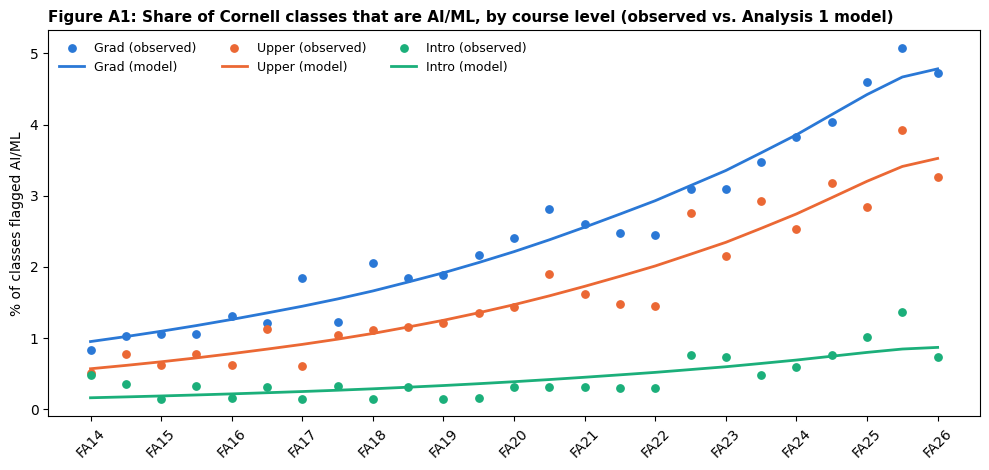

Observed % AI/ML by level, first semester (FA14), the low years, and the last semester (FA26):


course_level,Grad,Intro,Upper
semester,,,
FA14,0.84,0.49,0.52
FA26,4.73,0.74,3.26


Lowest and highest intro share from FA15 to SP22: [0.15, 0.33]
Fall 2026, observed vs. predicted % AI/ML:


,course_level,is_ai,predicted_a1
72,Grad,4.73,4.78
73,Intro,0.74,0.87
74,Upper,3.26,3.52


Largest misses:


,semester,course_level,is_ai,predicted_a1,miss (pct. points)
53,SP23,Upper,2.75,2.18,0.57
50,FA22,Upper,1.45,2.01,-0.56
70,SP26,Intro,1.37,0.85,0.52
71,SP26,Upper,3.92,3.41,0.51
48,FA22,Grad,2.46,2.93,-0.48


In [4]:
# Figure A1: dots = share of classes that are AI/ML in each semester and level; lines = the model's predictions.
classes["predicted_a1"] = a1.predict(sm.add_constant(classes[A1_INPUTS]))
by_level = classes.groupby(["term_index", "course_level"])[["is_ai", "predicted_a1"]].mean().reset_index()
by_level[["is_ai", "predicted_a1"]] = by_level[["is_ai", "predicted_a1"]] * 100   # as percents

colors = {"Grad": "#2a78d6", "Upper": "#eb6834", "Intro": "#1baf7a"}
plt.figure(figsize=(10, 4.8))
for level, color in colors.items():
    d = by_level[by_level["course_level"] == level]
    plt.scatter(d["term_index"], d["is_ai"], color=color, s=28, label=f"{level} (observed)")
    plt.plot(d["term_index"], d["predicted_a1"], color=color, linewidth=2, label=f"{level} (model)")
plt.xticks(semester_names.index[::2], semester_names.iloc[::2], rotation=45)
plt.ylabel("% of classes flagged AI/ML")
plt.title("Figure A1: Share of Cornell classes that are AI/ML, by course level (observed vs. Analysis 1 model)",
          loc="left", fontsize=11, fontweight="bold")
plt.legend(frameon=False, ncol=3, fontsize=9)
plt.tight_layout()
plt.show()

# Predicting: the latest semester. Oddities: the semesters and levels the model misses by the most.
by_level["semester"] = by_level["term_index"].map(semester_names)
by_level["miss (pct. points)"] = by_level["is_ai"] - by_level["predicted_a1"]
print("Observed % AI/ML by level, first semester (FA14), the low years, and the last semester (FA26):")
display(by_level.pivot(index="semester", columns="course_level", values="is_ai").loc[["FA14", "FA26"]].round(2))
print("Lowest and highest intro share from FA15 to SP22:",
      by_level[(by_level["course_level"] == "Intro") & by_level["term_index"].between(2, 15)]["is_ai"].agg(["min", "max"]).round(2).tolist())
print("Fall 2026, observed vs. predicted % AI/ML:")
display(by_level[by_level["semester"] == "FA26"][["course_level", "is_ai", "predicted_a1"]].round(2))
print("Largest misses:")
display(by_level.sort_values("miss (pct. points)", key=abs, ascending=False).head(5)
        [["semester", "course_level", "is_ai", "predicted_a1", "miss (pct. points)"]].round(2))

**Analysis 1: using the summarize, predict, and oddities / outliers method from the rubric**
* **Summarize:** AI classes are multiplying at about the same speed at every level. Based on our findings, each year, the odds that a graduate class is AI/ML are multiplied by 1.156 (a 15.6% increase, 95% CI [Confidence Interval]: 11.4% to 20.0%). For intro classes the yearly increase is 15.9%, and for upper-level classes 17.5%. The trickle-down interaction is like zero: odds ratio 1.003 (95% CI 0.886 to 1.135, p = 0.967), so we find no backing for our hypothesis that intro courses grow faster. Our other preregistered expectation does hold, so intro classes start with much lower odds (odds ratio 0.169, p = 0.015). Last semester's Google Trends score has no effect once time is in the model (odds ratio 0.999 per point, p = 0.485).
* **Predict:** for Fall 2026 the model predicts that 0.87% of intro classes and 4.78% of graduate classes are AI/ML. The actual shares are 0.74% and 4.73%.
* **Outliers/oddities:** The model's biggest misses are a dip for upper-level courses in Fall 2022 and a jump for intro and upper-level courses in Spring 2026 (intro 1.37% vs. 0.85% predicted) that went back down in Fall 2026.

### Analysis 2: Is AI/ML spreading from computing into other disciplines?
We make the interaction input years × `is_computing`, fit the logistic regression on `listings`, and check our preregistered test β(years) > 0. A negative interaction means non-computing departments are growing faster than computing.

In [5]:
# Preregistered Analysis 2
listings["years_x_computing"] = listings["years_since_start"] * listings["is_computing"]
A2_INPUTS = ["years_since_start", "is_computing", "years_x_computing", "trends_lag1"]

a2 = fit_logit(listings, A2_INPUTS, cluster_col="department")
print(a2.summary())
print("\nTable A2. Analysis 2 as odds ratios")
display(odds_table(a2))

b2 = a2.params
growth_a2 = pd.Series({
    "Non-computing departments": np.exp(b2["years_since_start"]) - 1,
    "Computing (CS, INFO, STSCI)": np.exp(b2["years_since_start"] + b2["years_x_computing"]) - 1}) * 100
print("Yearly % change in the odds that a listing is AI/ML:")
print(growth_a2.round(1).to_string())
print(f"\nPreregistered test 2: beta(years) > 0 for non-computing listings?  beta = {b2['years_since_start']:.3f}, "
      f"p = {a2.pvalues['years_since_start']:.2g}")
print(f"Not preregistered (exploratory): beta(years x is_computing) = {b2['years_x_computing']:.3f}, "
      f"odds ratio = {np.exp(b2['years_x_computing']):.3f}, p = {a2.pvalues['years_x_computing']:.2g}")

                           Logit Regression Results                           
Dep. Variable:                  is_ai   No. Observations:                94190
Model:                          Logit   Df Residuals:                    94185
Method:                           MLE   Df Model:                            4
Date:                Tue, 10 Nov 2026   Pseudo R-squ.:                  0.1802
Time:                        10:27:13   Log-Likelihood:                -6880.6
converged:                       True   LL-Null:                       -8393.4
Covariance Type:              cluster   LLR p-value:                     0.000
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                -6.2065      0.287    -21.619      0.000      -6.769      -5.644
years_since_start     0.2213      0.022      9.856      0.000       0.177       0.265
is_computing          4.

,odds ratio,p-value,95% CI low,95% CI high
const,0.002,0.000,0.001,0.004
years_since_start,1.248,0.000,1.194,1.304
is_computing,72.718,0.000,32.615,162.131
years_x_computing,0.850,0.000,0.813,0.887
trends_lag1,1.000,0.787,0.997,1.002


Yearly % change in the odds that a listing is AI/ML:
Non-computing departments      24.8
Computing (CS, INFO, STSCI)     6.0

Preregistered test 2: beta(years) > 0 for non-computing listings?  beta = 0.221, p = 6.4e-23
Not preregistered (exploratory): beta(years x is_computing) = -0.163, odds ratio = 0.850, p = 2.4e-13


**Figure A2:** The left panel compares the actual and predicted proportion of AI/ML listings for computing and non-computing departments on a log scale. The right panel (not preregistered) counts how many non-computing departments list at least one AI/ML course each semester, which shows how widely AI is spreading in ways that a proportion can hide.

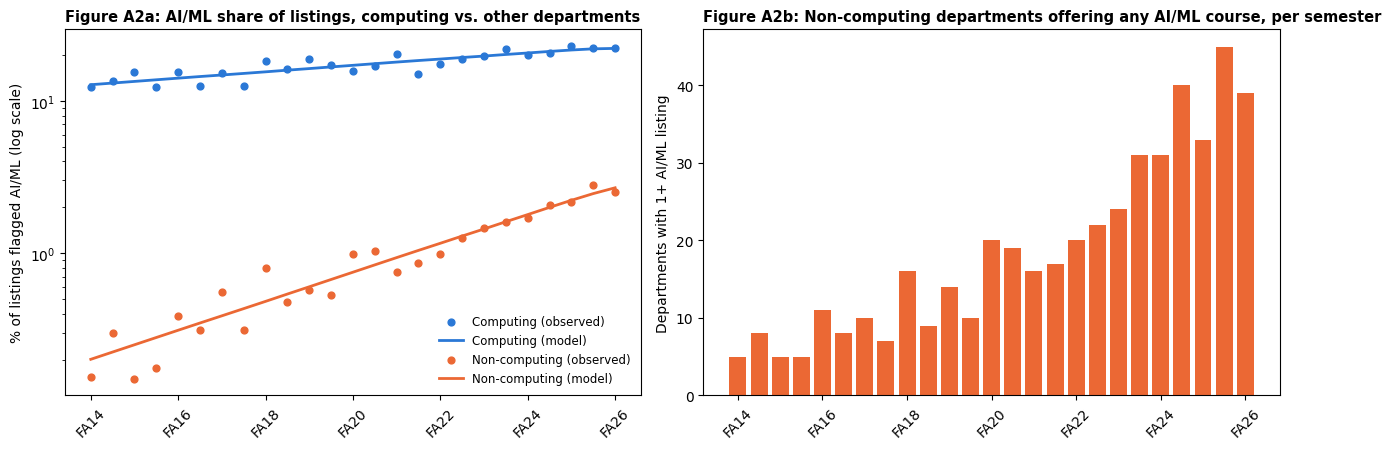

Observed % AI/ML listings, FA14 vs. FA26:


group,Computing,Non-computing
semester,,
FA14,12.40,0.15
FA26,22.16,2.54


Fall 2026, observed vs. predicted % AI/ML listings:


,group,is_ai,predicted_a2
48,Non-computing,2.54,2.69
49,Computing,22.16,22.10


Largest misses:


,semester,group,is_ai,predicted_a2,miss (pct. points)
31,SP22,Computing,14.95,18.40,-3.45
17,FA18,Computing,18.24,15.51,2.74
15,SP18,Computing,12.58,15.14,-2.56
21,FA19,Computing,18.79,16.29,2.50
29,FA21,Computing,20.22,17.97,2.24


Non-computing departments with any AI/ML listing: 5 in FA14 -> 39 in FA26 (most: 45)
Distinct AI/ML courses whose latest listing is outside Computing: 248 of 359 (69%)


In [6]:
# Figure A2a: share of AI/ML listings, computing vs. other departments
# Figure A2b (not preregistered): how many non-computing departments list at least one AI/ML course
listings["predicted_a2"] = a2.predict(sm.add_constant(listings[A2_INPUTS]))
by_group = listings.groupby(["term_index", "is_computing"])[["is_ai", "predicted_a2"]].mean().reset_index()
by_group[["is_ai", "predicted_a2"]] = by_group[["is_ai", "predicted_a2"]] * 100
non_computing = listings[listings["is_computing"] == 0]
departments_with_ai = non_computing.groupby(["term_index", "department"])["is_ai"].max().groupby("term_index").sum()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.6))
for comp, color, name in [(1, "#2a78d6", "Computing"), (0, "#eb6834", "Non-computing")]:
    d = by_group[by_group["is_computing"] == comp]
    ax1.scatter(d["term_index"], d["is_ai"], color=color, s=24, label=f"{name} (observed)")
    ax1.plot(d["term_index"], d["predicted_a2"], color=color, linewidth=2, label=f"{name} (model)")
ax1.set_yscale("log")
ax1.set_ylabel("% of listings flagged AI/ML (log scale)")
ax1.set_title("Figure A2a: AI/ML share of listings, computing vs. other departments", loc="left",
              fontsize=10.5, fontweight="bold")
ax1.legend(frameon=False, fontsize=8.5)
ax2.bar(departments_with_ai.index, departments_with_ai.values, color="#eb6834")
ax2.set_ylabel("Departments with 1+ AI/ML listing")
ax2.set_title("Figure A2b: Non-computing departments offering any AI/ML course, per semester", loc="left",
              fontsize=10.5, fontweight="bold")
for ax in (ax1, ax2):
    ax.set_xticks(semester_names.index[::4])
    ax.set_xticklabels(semester_names.iloc[::4], rotation=45)
plt.tight_layout()
plt.show()

by_group["group"] = by_group["is_computing"].map({1: "Computing", 0: "Non-computing"})
by_group["semester"] = by_group["term_index"].map(semester_names)
by_group["miss (pct. points)"] = by_group["is_ai"] - by_group["predicted_a2"]
print("Observed % AI/ML listings, FA14 vs. FA26:")
display(by_group.pivot(index="semester", columns="group", values="is_ai").loc[["FA14", "FA26"]].round(2))
print("Fall 2026, observed vs. predicted % AI/ML listings:")
display(by_group[by_group["semester"] == "FA26"][["group", "is_ai", "predicted_a2"]].round(2))
print("Largest misses:")
display(by_group.sort_values("miss (pct. points)", key=abs, ascending=False).head(5)
        [["semester", "group", "is_ai", "predicted_a2", "miss (pct. points)"]].round(2))
print(f"Non-computing departments with any AI/ML listing: {departments_with_ai.iloc[0]} in FA14 -> "
      f"{departments_with_ai.iloc[-1]} in FA26 (most: {departments_with_ai.max()})")
ai_course_list = course_history[course_history["ever_ai"] == 1]
outside = (ai_course_list["discipline"] != "Computing").sum()
print(f"Distinct AI/ML courses whose latest listing is outside Computing: {outside} of {len(ai_course_list)} "
      f"({outside / len(ai_course_list):.0%})")

**What Analysis 2 shows:**
* **Summarize:** each year, the odds that a non-computing listing is AI/ML are multiplied by 1.248. This is a 24.8% increase, so **our hypothesis was supported.** Computing departments grow 6.0% per year. The exploratory interaction shows that other fields are growing about four times faster, but from a much lower starting point: 0.15% → 2.54% of non-computing listings vs. 12.4% → 22.2% in computing, Fall 2014 to Fall 2026.
* **Predict:** the model expects 2.69% of non-computing listings to be AI/ML in Fall 2026 (actual: 2.54%) and 22.10% in computing (actual: 22.16%).
* **Outliers/oddities:** All of the biggest misses are in Computing, which jumps around by up to 3.5 percentage points from the model's prediction (e.g., Spring 2022: 15.0% vs. 18.4% predicted).

### Checking the Google Trends spike (reviewer question 1)
Our Trends index jumps to 100 in Spring 2026, compared with 47 the semester before. Our models use the previous semester's value, so the spike only shows up in our models in Fall 2026.

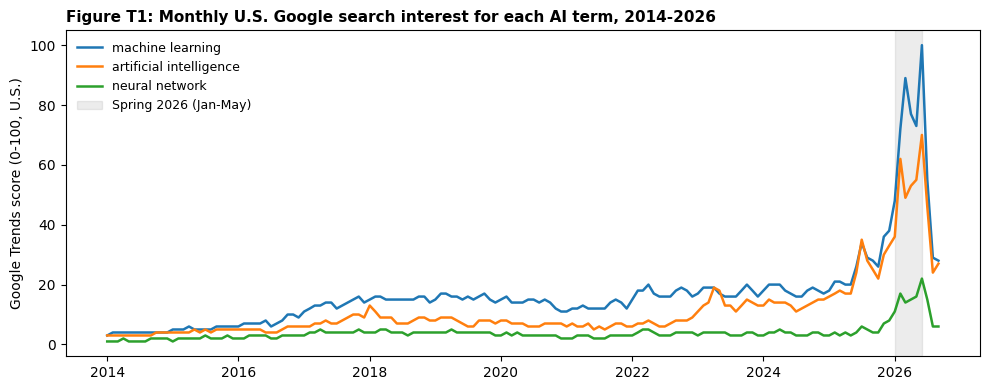

,Fall 2025 average,Spring 2026 average,increase,share of the total increase
machine learning,31.4,71.8,40.4,0.55
artificial intelligence,27.6,51.0,23.4,0.32
neural network,5.6,14.6,9.0,0.12


Monthly values from October 2025:


,machine learning,artificial intelligence,neural network
date,,,
2025-10-01,26,22,4
2025-11-01,36,30,7
2025-12-01,38,33,8
2026-01-01,48,36,11
2026-02-01,72,62,17
2026-03-01,89,49,14
2026-04-01,77,53,15
2026-05-01,73,55,16
2026-06-01,100,70,22


In [7]:
# Reviewer question 1: plot each Google Trends search term by month to see which one causes the Spring 2026 spike.
TERMS = ["machine learning", "artificial intelligence", "neural network"]
plt.figure(figsize=(10, 4))
for term in TERMS:
    plt.plot(trends_monthly["date"], trends_monthly[term], linewidth=1.8, label=term)
plt.axvspan(pd.Timestamp("2026-01-01"), pd.Timestamp("2026-05-31"), color="grey", alpha=0.15,
            label="Spring 2026 (Jan-May)")
plt.ylabel("Google Trends score (0-100, U.S.)")
plt.title("Figure T1: Monthly U.S. Google search interest for each AI term, 2014-2026", loc="left",
          fontsize=11, fontweight="bold")
plt.legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

# How much did each term go up from Fall 2025 to Spring 2026
fall25 = trends_monthly[(trends_monthly["date"] >= "2025-08-01") & (trends_monthly["date"] <= "2025-12-31")][TERMS].mean()
spring26 = trends_monthly[(trends_monthly["date"] >= "2026-01-01") & (trends_monthly["date"] <= "2026-05-31")][TERMS].mean()
change = pd.DataFrame({"Fall 2025 average": fall25, "Spring 2026 average": spring26})
change["increase"] = change["Spring 2026 average"] - change["Fall 2025 average"]
change["share of the total increase"] = change["increase"] / change["increase"].sum()
display(change.round(2))
print("Monthly values from October 2025:")
display(trends_monthly[trends_monthly["date"] >= "2025-10-01"].set_index("date")[TERMS])

What caused the spike: all terms went up starting in late 2025, peaked in June 2026, and went back down to Fall 2025 levels by August 2026. "Machine learning" makes up about 55% of the increase from Fall 2025 to Spring 2026, "artificial intelligence" at 32%, and "neural network" at 12%. Since every term jumps at the same time, it is not a problem with a single month's value. It could be attributed to increased interest or a change on Google's side of the data, but it only affects Fall 2026 in our models. We could not confirm whether the spike is an actual rise in interest, so we keep it as our reviewer advised and show that removing the only semester it affects does not change our findings.

**Does it change our results?** No. As our reviewer suggested, we keep the data and re-run both models without Fall 2026 (Tables R1 and R2): the trickle-down odds ratio becomes 1.008 (p = 0.90), and non-computing odds still grow 22.7% per
year.

### Does the catalog actually follow public interest?
We look at a model without time (does Trends go along with AI courses at all?) and in our preregistered models with time (does Trends explain anything beyond steady growth?). Google Trends also rises over time, so this comparison shows how much of the Google Trends effect is just time.

In [8]:
# Does the catalog track public interest?
# We compare the Google Trends coefficient with our preregistered models with and without time.
rows = []
for name, data, inputs, cluster in [
        ("Analysis 1, Trends only (no time)", classes, ["is_intro", "is_upper", "trends_lag1"], "crse_id"),
        ("Analysis 1, Trends + time (preregistered)", classes, A1_INPUTS, "crse_id"),
        ("Analysis 2, Trends only (no time)", listings, ["is_computing", "trends_lag1"], "department"),
        ("Analysis 2, Trends + time (preregistered)", listings, A2_INPUTS, "department")]:
    m = fit_logit(data, inputs, cluster)
    rows.append({"model": name, "odds ratio per +10 Trends points": np.exp(10 * m.params["trends_lag1"]),
                 "p-value": m.pvalues["trends_lag1"]})
print("Table T2. Effect of last semester's Google Trends score")
display(pd.DataFrame(rows).set_index("model").round(3))

per_semester = classes.groupby("term_index")[["is_ai", "years_since_start", "trends_lag1"]].mean()
print("Correlation of each semester's AI share with:")
print(per_semester.corr()["is_ai"].drop("is_ai").round(2).to_string())

Table T2. Effect of last semester's Google Trends score


,odds ratio per +10 Trends points,p-value
model,,
"Analysis 1, Trends only (no time)",1.143,0.000
"Analysis 1, Trends + time (preregistered)",0.991,0.485
"Analysis 2, Trends only (no time)",1.158,0.000
"Analysis 2, Trends + time (preregistered)",0.996,0.787


Correlation of each semester's AI share with:
years_since_start    0.95
trends_lag1          0.69


Without time in the model, a 10 point rise in last semester's Google Trends score goes with 14–16% higher odds that a course is AI/ML. Once time is in the model, that effect disappears. Each semester's AI share is correlated with time at r = 0.95 but with Google Trends at only r = 0.69. The catalog and public interest travel in the same direction, but jumps in interest in Trends aren't reflected by increased AI courses the next semester. The catalog grows steadily, which makes sense because new courses take time to design and implement.

### More solid checks
Each row re-runs one of our preregistered models with one change, so we can see if our conclusions depend on that choice. "Without the grad twin copies" (Analysis 1) and "is_computing_broad", along with "without cross-listed courses" (Analysis 2) are preregistered. "Without Fall 2026" answers reviewer question 1, and the hand-checked flags answer reviewer question 2. We checked every intro course but only a sample of the others, so the hand-checked rows mostly test whether mistakes among the intro courses change Analysis 1. "Without Google Trends" shows whether the Trends input changes the time results.

In [9]:
# Robustness checks: re-run each preregistered model with one change.
def a1_check(name, data, outcome="is_ai", inputs=A1_INPUTS):
    m = fit_logit(data, inputs, "crse_id", outcome)
    p = m.params
    return {"check": name, "rows": int(m.nobs),
            "odds ratio years x intro": np.exp(p["years_x_intro"]), "p-value": m.pvalues["years_x_intro"],
            "Grad % per year": 100 * (np.exp(p["years_since_start"]) - 1),
            "Intro % per year": 100 * (np.exp(p["years_since_start"] + p["years_x_intro"]) - 1)}

def a2_check(name, data, outcome="is_ai", computing="is_computing", inputs=None):
    d = data.copy()
    d["comp"] = d[computing]
    d["years_x_comp"] = d["years_since_start"] * d["comp"]
    m = fit_logit(d, inputs or ["years_since_start", "comp", "years_x_comp", "trends_lag1"], "department", outcome)
    p = m.params
    return {"check": name, "rows": int(m.nobs),
            "Non-computing % per year": 100 * (np.exp(p["years_since_start"]) - 1),
            "p-value (years)": m.pvalues["years_since_start"],
            "odds ratio years x computing": np.exp(p["years_x_comp"]),
            "p-value (interaction)": m.pvalues["years_x_comp"]}

no_trends_a1 = [x for x in A1_INPUTS if x != "trends_lag1"]
a1_rows = [a1_check("Preregistered model", classes),
           a1_check("Without Fall 2026 (reviewer Q1)", classes[classes["roster"] != "FA26"]),
           a1_check("Without the grad twin copies (preregistered check, reviewer Q5)",
                    classes[classes["is_upper_twin_copy"] == 0]),
           a1_check("Without Google Trends", classes, inputs=no_trends_a1)]
a2_rows = [a2_check("Preregistered model", listings),
           a2_check("Without Fall 2026 (reviewer Q1)", listings[listings["roster"] != "FA26"]),
           a2_check("is_computing_broad: engineering counts as computing (preregistered check)", listings,
                    computing="is_computing_broad"),
           a2_check("Without cross-listed courses (preregistered check)", listings[listings["is_crosslisted"] == 0]),
           a2_check("Without Google Trends", listings, inputs=["years_since_start", "comp", "years_x_comp"])]
if "is_ai_reviewed" in classes.columns:
    a1_rows += [a1_check("Hand-checked flag (TEACH + DISCUSS)", classes, outcome="is_ai_reviewed"),
                a1_check("Hand-checked flag (TEACH only)", classes, outcome="is_ai_teach")]
    a2_rows += [a2_check("Hand-checked flag (TEACH + DISCUSS)", listings, outcome="is_ai_reviewed"),
                a2_check("Hand-checked flag (TEACH only)", listings, outcome="is_ai_teach")]
print("Table R1. Analysis 1 checks")
display(pd.DataFrame(a1_rows).set_index("check").round(3))
print("Table R2. Analysis 2 checks")
display(pd.DataFrame(a2_rows).set_index("check").round(3))

Table R1. Analysis 1 checks


,rows,odds ratio years x intro,p-value,Grad % per year,Intro % per year
check,,,,,
Preregistered model,75082,1.003,0.967,15.574,15.876
Without Fall 2026 (reviewer Q1),71942,1.008,0.904,13.728,14.680
"Without the grad twin copies (preregistered check, reviewer Q5)",67600,1.002,0.974,15.311,15.552
Without Google Trends,75082,1.003,0.967,15.122,15.421
Hand-checked flag (TEACH + DISCUSS),75082,1.230,0.039,15.867,42.514
Hand-checked flag (TEACH only),75082,1.415,0.000,15.746,63.777


Table R2. Analysis 2 checks


,rows,Non-computing % per year,p-value (years),odds ratio years x computing,p-value (interaction)
check,,,,,
Preregistered model,94190,24.767,0.0,0.850,0.000
Without Fall 2026 (reviewer Q1),90249,22.663,0.0,0.849,0.000
is_computing_broad: engineering counts as computing (preregistered check),94190,24.679,0.0,0.905,0.012
Without cross-listed courses (preregistered check),62302,26.048,0.0,0.833,0.000
Without Google Trends,94190,24.513,0.0,0.850,0.000
Hand-checked flag (TEACH + DISCUSS),94190,26.818,0.0,0.840,0.000
Hand-checked flag (TEACH only),94190,27.118,0.0,0.839,0.000


**What the checks show:**
* **Analysis 1:** with our keyword flag, the trickle-down odds ratio stays between 1.002 and 1.008 without Fall 2026, the twin copies, and Google Trends. With the manually checked flag, it changes: the odds ratio becomes 1.230 (p = 0.039), and intro odds grow 42.5% per year instead of 15.9% (TEACH only: 1.415, p < 0.001). This is actually because 44 of the 72 intro AI class-semesters were MENTION false positives, mostly Introduction to Data Science (INFO 2950) and Networks (ECON 2040) (counted in the table below). Without them, intro AI is almost zero until 2021. We checked every intro course but only a sample of graduate courses, so some graduate false positives might remain, which could make intro growth look faster than it really is.
* **Analysis 2:** non-computing odds grow 22.7%–27.1% per year in every check, including both hand-checked flags, and non-computing always grows faster than computing. Dropping cross-listed courses makes growth slightly faster. Counting engineering as computing makes the gap the smallest.

In [10]:
# Count the intro AI class-semesters our hand labels call MENTION, and which courses they are
intro_flagged = classes[(classes["course_level"] == "Intro") & (classes["is_ai"] == 1)]
mention = intro_flagged[intro_flagged["ai_label"] == "MENTION"]
print(f"Intro AI class-semesters (keyword flag): {len(intro_flagged)}, labeled MENTION: {len(mention)}")
print(mention.groupby(["subject", "catalog_nbr", "title"]).size().sort_values(ascending=False).to_string())

# Intro AI class-semesters per academic year, keyword flag vs. hand-checked flags
display(classes[classes["course_level"] == "Intro"]
        .groupby("academic_year")[["is_ai", "is_ai_reviewed", "is_ai_teach"]].sum().T)

Intro AI class-semesters (keyword flag): 72, labeled MENTION: 44
subject  catalog_nbr  title                                                                
INFO     2950         Introduction to Data Science                                             16
ECON     2040         Networks                                                                 12
PLBIO    2490         Hollywood Biology: Science in Cinema                                      6
ILRHR    2685         Building Better Jobs: Organizational Levers for Improving Job Quality     4
PLSCI    2490         Hollywood Biology: Science in Cinema                                      2
BIOPL    2490         Hollywood Biology: Science in Cinema                                      1
ECON     2850         Networks                                                                  1
INFO     2300         Server-Side Web Development                                               1
         2310         Interactive Web Development          

academic_year,2014–15,2015–16,2016–17,2017–18,2018–19,2019–20,2020–21,2021–22,2022–23,2023–24,2024–25,2025–26,2026–27
is_ai,5,3,3,3,3,2,4,4,7,8,9,16,5
is_ai_reviewed,2,0,0,0,0,0,1,1,2,4,6,10,2
is_ai_teach,0,0,0,0,0,0,1,1,1,3,6,7,1


### How good is our keyword flag (reviewer question 2)
These tables summarize our manual labels from cleaning Steps 14b–14c. We checked all 19 intro courses, a random sample of 30 of the other 340 flagged courses, and 30 unflagged courses with AI-sounding titles. A flag stays valid if the course is labeled as TEACH or DISCUSS. Since the 30 other courses were randomly selected, the share that holds up among them is an estimate for all of the upper level and graduate flags, but since it is only 30, it is a rough estimate.

In [11]:
# How many keyword flags hold up when we read the descriptions ourselves?
if os.path.exists("ai_labels_final.csv"):
    labels = pd.read_csv("ai_labels_final.csv").merge(
        course_history[["crse_id", "subject", "catalog_nbr", "title", "discipline", "first_ai_level"]], on="crse_id")
    labels = labels[labels["final_label"] != "UNRESOLVED"]
    print("Table L1. Share of courses with each label, by the level of their first AI semester")
    display(pd.crosstab(labels["first_ai_level"], labels["final_label"], normalize="index").round(2))
    print("Table L2. Share of courses with each label, by discipline")
    display(pd.crosstab(labels["discipline"], labels["final_label"], normalize="index").round(2))
    kept = labels["final_label"].isin(["TEACH", "DISCUSS"]).mean()
    double = labels[labels["n_labelers"] > 1]
    print(f"Flags kept (TEACH or DISCUSS): {kept:.0%} of {len(labels)} courses. "
          f"Labelers agreed on {double['agreed'].mean():.0%} of the {len(double)} courses labeled by 2+ people.")
    print("\nAll intro-level AI courses:")
    display(labels[labels["first_ai_level"] == "Intro"][["subject", "catalog_nbr", "title", "final_label"]])
    if os.path.exists("fn_labels_final.csv"):
        fn = pd.read_csv("fn_labels_final.csv")
        missed = fn[fn["label"].isin(["TEACH", "DISCUSS"])]
        print(f"Unflagged AI-adjacent courses checked: {len(fn)}; actually AI/ML: {len(missed)}")
        display(missed[["subject", "catalog_nbr", "title", "label"]])
else:
    print("ai_labels_final.csv not found: the hand labels have not been merged yet (see cleaning Step 14c).")

Table L1. Share of courses with each label, by the level of their first AI semester


final_label,DISCUSS,MENTION,TEACH
first_ai_level,,,
Grad,0.26,0.09,0.65
Intro,0.42,0.32,0.26
Upper,0.29,0.29,0.43


Table L2. Share of courses with each label, by discipline


final_label,DISCUSS,MENTION,TEACH
discipline,,,
Computing,0.13,0.27,0.60
Engineering & Math,0.09,0.09,0.82
Humanities & Arts,0.50,0.00,0.50
Natural & Life Sciences,0.50,0.25,0.25
"Social Sciences, Business & Law",0.59,0.24,0.18


Flags kept (TEACH or DISCUSS): 80% of 49 courses. Labelers agreed on 32% of the 19 courses labeled by 2+ people.

All intro-level AI courses:


,subject,catalog_nbr,title,final_label
0,COGST,1101,Introduction to Cognitive Science,DISCUSS
1,FSAD,1140,Principles of Design Computing,TEACH
4,CS,1700,Understanding Artificial Intelligence,TEACH
5,INFO,2300,Server-Side Web Development,MENTION
7,INFO,2950,Introduction to Data Science,MENTION
8,ECON,2850,Networks,MENTION
9,PLSCI,2490,Hollywood Biology: Science in Cinema,MENTION
10,ANTHR,1182,"FWS: Limits of the Human: Aliens, Apes, and Ar...",DISCUSS
13,ECE,2720,Data Science for Engineers,TEACH
18,HD,2940,Data Science for Social Scientists II,TEACH


Unflagged AI-adjacent courses checked: 30; actually AI/ML: 2


,subject,catalog_nbr,title,label
17,INFO,5610,"Sensors, Systems and Algorithms for Precision ...",DISCUSS
27,CS,7890,Seminar in Theory of Algorithms and Computing,DISCUSS


Of the 19 intro courses, 13 are stable and 6 are MENTION false positives, including Networks and Introduction to Data Science. Among the 30 randomly sampled flagged courses, 26 hold up, and 4 are MENTION false positives. Since 39 of the 49 courses are ok, most flags are right, but the intro group has the most false positives, even though it's a small number of them.

For the 19 intro courses, all three of us agreed on only 6 (32%), but at least two of us agreed on every course. All of our disagreements involved DISCUSS: whether a course teaches AI or just discusses it, or discusses it or only mentions it. This was obviously subjective to a degree but still usable information because we all followed the same written rule.

## Evaluation of Significance
To check our two preregistered tests in another way, we also use a permutation test and a bootstrap. We shuffle and resample whole courses (from Analysis 1) or shuffle within departments (for Analysis 2), because rows from the same course or department aren't independent, and these tests don't depend on the regression's assumptions. Figure S1 shows the 500 shuffled trickle-down coefficients (grey) against our real one (green).

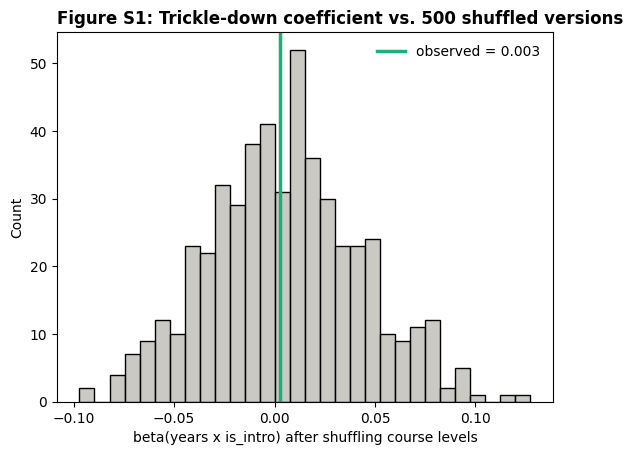

One-sided p-value (share of shuffled betas >= observed): 0.520
Two-sided p-value (share of |shuffled betas| >= |observed|): 0.948


In [12]:
# Permutation test for Analysis 1
# Null hypothesis: a course's level has nothing to do with how its AI status changes over time.
# We give each course one level (its first) and shuffle which level goes with which course.
# Each course keeps all of its semesters.
course_levels = classes.groupby("crse_id")["course_level"].first()
observed_a1 = a1.params["years_x_intro"]

n_perm = 500
perm_coefs = np.zeros(n_perm)
shuffled_data = classes.copy()
for i in range(n_perm):
    shuffled_levels = np.random.choice(course_levels.values, len(course_levels), replace=False)  # = a permutation
    new_level = shuffled_data["crse_id"].map(dict(zip(course_levels.index, shuffled_levels)))
    shuffled_data["is_intro"] = (new_level == "Intro").astype(int)
    shuffled_data["is_upper"] = (new_level == "Upper").astype(int)
    shuffled_data["years_x_intro"] = shuffled_data["years_since_start"] * shuffled_data["is_intro"]
    shuffled_data["years_x_upper"] = shuffled_data["years_since_start"] * shuffled_data["is_upper"]
    model = sm.Logit(shuffled_data["is_ai"], sm.add_constant(shuffled_data[A1_INPUTS])).fit(disp=0)
    perm_coefs[i] = model.params["years_x_intro"]

seaborn.histplot(perm_coefs, bins=30, color="#b9b8b1")
plt.axvline(observed_a1, color="#1baf7a", linewidth=2.5, label=f"observed = {observed_a1:.3f}")
plt.xlabel("beta(years x is_intro) after shuffling course levels")
plt.title(f"Figure S1: Trickle-down coefficient vs. {n_perm} shuffled versions", loc="left", fontweight="bold")
plt.legend(frameon=False)
plt.show()
print(f"One-sided p-value (share of shuffled betas >= observed): {np.mean(perm_coefs >= observed_a1):.3f}")
print(f"Two-sided p-value (share of |shuffled betas| >= |observed|): "
      f"{np.mean(np.abs(perm_coefs) >= abs(observed_a1)):.3f}")

**Bootstrap for Analysis 1:** we resample courses with replacement, re-fit, and keep the middle 95% as our confidence interval.

In [13]:
# Bootstrap confidence interval for the same coefficient
# We resample courses because the rows of one course are not independent.
course_ids = classes["crse_id"].unique()
rows_of_course = classes.groupby("crse_id").indices
n_boot = 500
boot_coefs = np.zeros(n_boot)
for i in range(n_boot):
    sampled_courses = np.random.choice(course_ids, len(course_ids), replace=True)
    sample = classes.iloc[np.concatenate([rows_of_course[c] for c in sampled_courses])]
    model = sm.Logit(sample["is_ai"], sm.add_constant(sample[A1_INPUTS])).fit(disp=0)
    boot_coefs[i] = model.params["years_x_intro"]

low, high = np.percentile(boot_coefs, [2.5, 97.5])
print(f"95% bootstrap confidence interval for beta(years x is_intro): [{low:.3f}, {high:.3f}]")
print(f"As odds ratios: [{np.exp(low):.2f}, {np.exp(high):.2f}]  (1 = intro and grad odds grow at the same speed)")

95% bootstrap confidence interval for beta(years x is_intro): [-0.091, 0.220]
As odds ratios: [0.91, 1.25]  (1 = intro and grad odds grow at the same speed)


**Permutation test for Analysis 2:** we shuffle which semester each listing belongs to *within its own department*, so
every department keeps its size and number of AI listings, then re-fit and record β(years).

In [14]:
# Permutation test for Analysis 2. Null hypothesis: within a department, AI listings are no more likely in later semesters.
# We shuffle which semester each listing belongs to within its own department.
# Each department keeps its size and its number of AI listings.
# Then we look up that semester's years and Trends value and refit
semester_years = listings.groupby("term_index")["years_since_start"].first()
semester_trends = listings.groupby("term_index")["trends_lag1"].first()
observed_a2 = a2.params["years_since_start"]

n_perm2 = 300
perm_coefs2 = np.zeros(n_perm2)
shuffled_data2 = listings.copy()
for i in range(n_perm2):
    shuffled_term = shuffled_data2.groupby("department")["term_index"].transform(lambda s: np.random.permutation(s.values))
    shuffled_data2["years_since_start"] = shuffled_term.map(semester_years)
    shuffled_data2["trends_lag1"] = shuffled_term.map(semester_trends)
    shuffled_data2["years_x_computing"] = shuffled_data2["years_since_start"] * shuffled_data2["is_computing"]
    model = sm.Logit(shuffled_data2["is_ai"], sm.add_constant(shuffled_data2[A2_INPUTS])).fit(disp=0)
    perm_coefs2[i] = model.params["years_since_start"]

print(f"Observed beta(years) = {observed_a2:.3f}; largest of {n_perm2} shuffled betas = {perm_coefs2.max():.3f}")
print(f"One-sided p-value (share of shuffled betas >= observed): {np.mean(perm_coefs2 >= observed_a2):.3f} "
      f"(none of the {n_perm2} shuffles reached it, so p < {1 / n_perm2:.3f})")

Observed beta(years) = 0.221; largest of 300 shuffled betas = 0.053
One-sided p-value (share of shuffled betas >= observed): 0.000 (none of the 300 shuffles reached it, so p < 0.003)


**Evaluation of significance continued: what the significance tests show**
* **Analysis 1:** the real coefficient is right in the middle of the shuffled coefficients (one-sided p = 0.52, two-sided p = 0.95). The 95% bootstrap confidence interval is −0.091 to 0.220, which as odds ratios is 0.91 to 1.25 and includes 1. We fail to reject the null hypothesis that intro and graduate courses grow at the same speed.
* **Analysis 2:** the real β(years) is 0.221, while the largest of 300 shuffled values is only 0.053 (p < 0.004). We reject the null hypothesis that non-computing listings are not becoming more likely to be AI/ML over time.

## Conclusions
1. **Across course levels:** AI/ML grew at every level, and graduate courses led at both the start and end of our data. Using our preregistered keyword flag, intro and graduate odds grew at about the same speed, so we find no support for trickle down. But, after our manual hand labels showed that most early intro "AI" courses were false positives, intro odds grow faster than graduate odds when we remove them in an exploratory check. Since we only checked a sample of graduate courses, we can't say this for sure.
2. **Across disciplines:** AI/ML is clearly spreading beyond computing. Non-computing odds grew 24.8% per year compared with 6.0% in computing, the number of non-computing departments containing an AI/ML course went from 5 to 39, and 69% of AI/ML courses are outside CS, INFO, and STSCI.
3. **Public interest:** the catalog moves in the same direction as Google search interest, but it doesn't react to it by semester. Trends adds little to no impact once steady growth over time is in the model.
4. **Taught or discussed:** in the courses we checked, AI in computing and engineering is mostly taught, while AI in the social sciences is mostly discussed. We can infer that AI is spreading into other fields as a topic more than a method.

## Limitations
1. **Keyword matching limitations**
   * False positives: Networks (CS 2850, cross-listed in ECON, INFO, and SOC) is flagged because "neural networks" appears in a topic list, and courses like CS 4820 (algorithms) and PLBIO 2490 (Hollywood Biology) mention AI but don't actually go through it.
   * False negatives: special topics type seminars that use ML but don't say so in their descriptions are probably missed.
   * If one misflagged course runs every semester, even that one error could make AI look falsely more widespread.
2. Neither `is_ai` nor `mentions_ai` indicates how much class time is spent on AI, which is very difficult to measure reliably.
3. **Undergraduate/graduate twins inflate the graduate count.** 36% of AI class-semesters are twins, and some of the graduate leads come from graduate versions of undergraduate courses, not separate graduate courses.
4. **We can't measure how many people actually take these AI/ML courses.** Since a 500 person lecture has the same weight as a 4 person graduate seminar, that limits our real data analysis.
5. **We do not know what happened before Fall 2014:** Courses that were already AI before 2014–15 look like they started right then. This makes the first year look like a burst of AI adoption by Cornell when it is really just the start of the measurement.
6. **Cross-listing might resemble class adoption.** In Analysis 2, a department gets credit for an AI course it cross-lists even if computing faculty teach it.
7. **Discipline groups can be subjective:** Some subjects could go in two groups, such as linguistics, cognitive science, and design, but we went with the best we could.
8. **Google Trends is a rough measure.** It rises over time along with everything else, making its independent effect hard to estimate. It also has that sharp peak.
9. **Real-world impact:** If administrators read our analysis at mere face value, they might infer that students outside CS / AI already have adequate access to AI courses and topics. However, our counts could have been inflated by false positives, cross-listings, and twin instances. And importantly, they ignore student enrollment count. This might lead to misallocation of resources, etc.

**Added in Phase III**

10. **Limits of our significance tests:** The intro group is 19 AI courses, meaning that a non-significant intro result does not necessarily mean there is no effect. Our model also assumes the log-odds change in a straight line over time, which Figure A1 shows is not always true for introductory courses. We also ran several stability / robust checks, so one of them could differ from the rest just by chance.
11. **Fall 2026 and the Trends lag:** Fall 2026 was still in progress when we collected the data, and a one-semester lag may be too short for course planning to react to public interest or hidden administrative decision-making processes.
12. **Hand labels:** We checked every intro course but only a sample of the others, so our corrected flags remove intro false positives more thoroughly than graduate ones. All three of us agreed on only 32% of the intro labels, so the labels themselves are a bit uncertain too.

## Reflection
* **18 subjects --> every subject:** Our first draft only used 18 subjects we picked by hand, which was too small and already biased towards finding AI where we expected it. After peer evaluation we scanned every subject, which took a few hours to download but let AI courses show up in places we wouldn't have guessed.
* **Cross-listed courses:** We completely ignored cross-listing at first, so one class could be counted up to four times. Now we keep two tables, one that counts each class once and one that counts each department listing (cleaning Step 9).
* **Instructor matching:** We wanted to match instructors to their publications to see if AI courses outside computing are taught by AI researchers, but matching names needs ORCID and other checks for every single person, which is not very reliable, so we left it out.

## Source Code
All of our code is on our GitHub: https://github.com/Aidennnnnnnnnn/2950-final-project. This includes `scrape_cornell.py` (data collection), our data cleaning notebook (which outputs every file this notebook loads), and this report.

## Acknowledgments and Bibliography
**Data:** Cornell University, Office of the University Registrar, Class Roster API (https://classes.cornell.edu/api/2.0/).
Google Trends (https://trends.google.com), downloaded with `pytrends` (https://github.com/GeneralMills/pytrends).

**Software:** pandas, NumPy, Matplotlib, seaborn, statsmodels, DuckDB, requests.

**People:** Our TA Jingruo Chen, whose Phase II feedback led us to make the Google Trends spike check, labeling rule, and twin course check, and our peer reviewers, who led us to collect every subject, handle cross-listed courses, and track courses by `crse_id`. Our peer reviewers provided feedback that we think really saved this project because beforehand, we were planning to scan around 20-30 specific courses alone, which was both too small and already biased towards AI/ML topics.

**AI tools:** Claude was used to suggest additional operations / analyses we could do on top of what we already had in mind to make our goals more complete. It helped teach us unfamiliar concepts, helped write and debug parts of our code, and helped suggest proofreading to our materials.

**References**
* Börner, K., Scrivner, O., Gallant, M., Ma, S., Liu, X., Chewning, K., Wu, L., & Evans, J. A. (2018). Skill discrepancies between research, education, and jobs reveal the critical need to supply soft skills for the data economy. *Proceedings of the National Academy of Sciences, 115*(50), 12630–12637. https://doi.org/10.1073/pnas.1804247115
* Computing Research Association. (2017). *Generation CS: Computer science undergraduate enrollments surge since 2006.* https://cra.org/data/Generation-CS/
* Cornell University Office of the University Registrar. (n.d.). *Class Roster API 2.0.* Retrieved October 2026, from https://classes.cornell.edu/api/2.0/
* Gebru, T., Morgenstern, J., Vecchione, B., Vaughan, J. W., Wallach, H., Daumé III, H., & Crawford, K. (2021). Datasheets for datasets. *Communications of the ACM, 64*(12), 86–92. https://doi.org/10.1145/3458723
* GeneralMills. (n.d.). *pytrends* [Computer software]. GitHub. https://github.com/GeneralMills/pytrends
* Google. (n.d.-a). *FAQ about Google Trends data.* Retrieved October 2026, from https://support.google.com/trends/answer/4365533
* Google. (n.d.-b). *Google Trends.* Retrieved October 2026, from https://trends.google.com

## Questions for Reviewers
1. We hand-checked every intro course but only 30 of the 340 other flagged courses. Should we label more graduate and upper-level courses before Phase IV so the corrected Analysis 1 is fair to both levels, or is it okay to keep it as an exploratory check?
2. All three of us only agreed on 32% of the intro labels, and every disagreement involved DISCUSS. Should we make the DISCUSS rule more specific and re-label, or just report the disagreement?
3. We currently lag Google Trends by one semester, but would trying a two-semester lag as an exploratory check make sense, since course planning might take longer than that?